## Real cell expression profiles compared to DIFFscBERT generated samples

In [1]:
from pathlib import Path
from scipy import sparse
from matplotlib.lines import Line2D

import torch
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
PROJECT_ROOT = Path.cwd()
REAL_DATA_FILE = PROJECT_ROOT.parent.parent / "DATASET" / "preprocessed_data.h5ad"
GENERATED_DIR = PROJECT_ROOT.parent / "results_4cts" / "generate" 
OUTPUT_DIR = PROJECT_ROOT.parent / "results_4cts" / "umap"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
cell_types = [
    "CD4-positive helper T cell",
    "malignant cell",
    "CD8-positive, alpha-beta regulatory T cell",
    "vein endothelial cell",
]
cell_type_colors = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]

celltype_1_name = "CD4-positive helper T cell"
celltype_2_name = "malignant cell"
celltype_3_name = "CD8-positive, alpha-beta regulatory T cell"
celltype_4_name = "vein endothelial cell"

Generated samples

CD4-positive helper T cell: (300, 16906)
malignant cell: (300, 16906)
AnnData object with n_obs × n_vars = 1200 × 16906
    obs: 'cell_type'
    uns: 'cell_type_colors'
Genes with non-zero variance: 16905 / 16906


/storage_1/akumbara/miniconda3/envs/diffscbert_4090/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/storage_1/akumbara/miniconda3/envs/diffscbert_4090/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


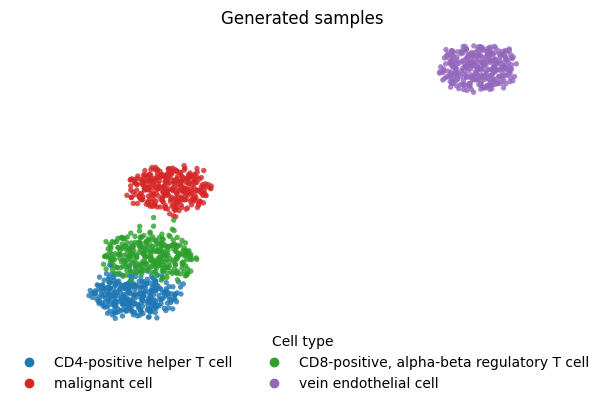

In [4]:
# Paths to the generated tensors
file_celltype_1 = GENERATED_DIR / "CD4-positive_helper_T_cell_300_DIFFscBERT.pt"
file_celltype_2 = GENERATED_DIR / "malignant_cell_300_DIFFscBERT.pt"
file_celltype_3 = GENERATED_DIR / "CD8-positive,_alpha-beta_regulatory_T_cell_300_DIFFscBERT.pt"
file_celltype_4 = GENERATED_DIR / "vein_endothelial_cell_300_DIFFscBERT.pt"

# Load generated matrices -> [number_of_cells, number_of_genes]
matrix_1 = torch.load(file_celltype_1, map_location="cpu")
matrix_2 = torch.load(file_celltype_2, map_location="cpu")
matrix_3 = torch.load(file_celltype_3, map_location="cpu")
matrix_4 = torch.load(file_celltype_4, map_location="cpu")

if isinstance(matrix_1, torch.Tensor):
    matrix_1 = matrix_1.numpy()
if isinstance(matrix_2, torch.Tensor):
    matrix_2 = matrix_2.numpy()
if isinstance(matrix_3, torch.Tensor):
    matrix_3 = matrix_3.numpy()
if isinstance(matrix_4, torch.Tensor):
    matrix_4 = matrix_4.numpy()

matrix_1 = np.asarray(matrix_1, dtype=np.float32)
matrix_2 = np.asarray(matrix_2, dtype=np.float32)
matrix_3 = np.asarray(matrix_3, dtype=np.float32)
matrix_4 = np.asarray(matrix_4, dtype=np.float32)

print(f"{celltype_1_name}: {matrix_1.shape}")
print(f"{celltype_2_name}: {matrix_2.shape}")

if matrix_1.ndim != 2 or matrix_2.ndim != 2:
    raise ValueError("Each generated matrix must have shape [cells, genes].")

if matrix_1.shape[1] != matrix_2.shape[1]:
    raise ValueError(
        "The two matrices have different numbers of genes: "
        f"{matrix_1.shape[1]} and {matrix_2.shape[1]}."
    )

# Combine generated cells
combined_matrix = np.concatenate(
    [matrix_1, matrix_2, matrix_3, matrix_4],
    axis=0,
)

celltype_labels = (
    [celltype_1_name] * matrix_1.shape[0]
    + [celltype_2_name] * matrix_2.shape[0]
    + [celltype_3_name] * matrix_3.shape[0]
    + [celltype_4_name] * matrix_4.shape[0]
)

# Create AnnData object
adata_generated = sc.AnnData(X=combined_matrix)
adata_generated.obs["cell_type"] = pd.Categorical(
    celltype_labels, categories=cell_types, ordered=True
)
adata_generated.uns["cell_type_colors"] = cell_type_colors
adata_generated.obs_names = [f"generated_cell_{i}" for i in range(adata_generated.n_obs)]
adata_generated.var_names = [f"gene_{i}" for i in range(adata_generated.n_vars)]
adata_generated.var_names_make_unique()
print(adata_generated)

# Remove genes with no variation across generated cells
# Constant genes do not contribute to PCA or UMAP
gene_variance = np.var(adata_generated.X, axis=0)
variable_gene_mask = gene_variance > 0
print(f"Genes with non-zero variance: {variable_gene_mask.sum()} / {adata_generated.n_vars}")
adata_umap = adata_generated[:, variable_gene_mask].copy()

# Preprocessing: since these are discrete expression bins rather than raw counts,
# do not apply normalize_total or log1p automatically.
# Scaling prevents genes with larger variance from dominating PCA.
sc.pp.scale(adata_umap, zero_center=True, max_value=10)

# PCA
max_pcs = min(50, adata_umap.n_obs - 1, adata_umap.n_vars - 1)

if max_pcs < 2:
    raise ValueError(
        "Not enough cells or variable genes to calculate PCA and UMAP."
    )

sc.tl.pca(adata_umap, n_comps=max_pcs, svd_solver="arpack")

# Nearest-neighbor graph
n_neighbors = min(15, adata_umap.n_obs - 1)
sc.pp.neighbors(adata_umap, n_neighbors=n_neighbors, n_pcs=max_pcs)

# UMAP
sc.tl.umap(adata_umap, random_state=42)

# Plot
fig, ax = plt.subplots(figsize=(5, 4))

sc.pl.umap(
    adata_umap,
    color="cell_type",
    title="Generated samples",
    size=60,
    alpha=0.8,
    frameon=False,
    legend_loc=None,   
    ax=ax,
    show=False,
)

# Make handles using the same category colors
handles = [
    plt.Line2D(
        [], [], marker="o", linestyle="",
        color=cell_type_colors[i], label=cell_types[i],
        markersize=6,
    )
    for i in range(len(cell_types))
]

fig.legend(
    handles=handles,
    title="Cell type",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=False,
)

fig.tight_layout(rect=[0, 0.12, 1, 1])  # reserve space below for legend
fig.savefig(OUTPUT_DIR / "generated_umap.png", dpi=300, bbox_inches="tight")
plt.show()

Real cell expression profiles

CD4-positive helper T cell: 419 available cells
malignant cell: 240614 available cells
CD8-positive, alpha-beta regulatory T cell: 14180 available cells
vein endothelial cell: 10318 available cells

Sampled AnnData:
AnnData object with n_obs × n_vars = 1200 × 16906
    obs: 'tissue_ontology_term_id', 'tissue_type', 'assay_ontology_term_id', 'disease_ontology_term_id', 'cell_type_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'donor_id', 'suspension_type', 'grade', 'author_cell_type', 'batch', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'n_genes'
    uns: 'log1p'

Sampled cells per cell type:
CD4-positive helper T cell                    300
malignant cell                                300
CD8-positive, alpha-beta regulatory T cell    300
vein endothelial cell                         300
Name: cell_type, dtype: int6

/storage_1/akumbara/miniconda3/envs/diffscbert_4090/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


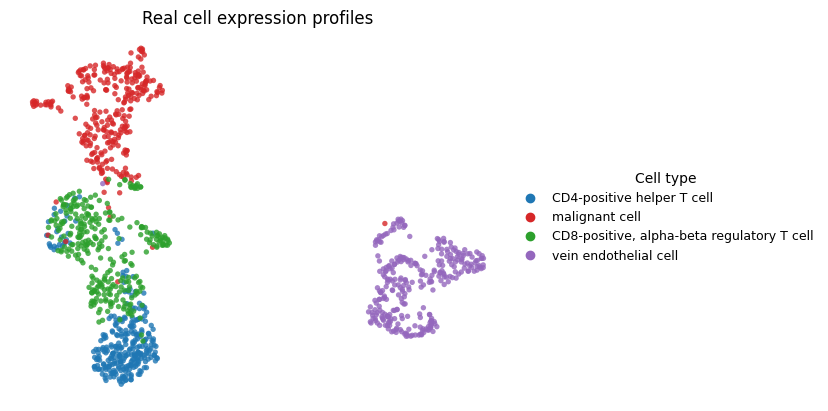

In [5]:
# import numpy as np
# import pandas as pd
# import scanpy as sc
# from scipy import sparse
# import matplotlib.pyplot as plt

# cell_types = [
#     "CD4-positive helper T cell",
#     "malignant cell",
#     "CD8-positive, alpha-beta regulatory T cell",
#     "vein endothelial cell",
# ]
# cell_type_colors = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]

# Load real preprocessed data
data = sc.read_h5ad(REAL_DATA_FILE)

n_cells_per_type = 300
random_seed = 42

# Check that the requested cell types are present
available_cell_types = set(data.obs["cell_type"].astype(str))
missing_cell_types = [cell_type for cell_type in cell_types if cell_type not in available_cell_types]

if missing_cell_types:
    raise ValueError(
        "The following cell types are not present in the dataset: "
        f"{missing_cell_types}"
    )

# Sample exactly 100 cells per cell type
rng = np.random.default_rng(random_seed)
sampled_indices = []

cell_type_array = data.obs["cell_type"].astype(str).to_numpy()

for cell_type in cell_types:
    cell_indices = np.flatnonzero(cell_type_array == cell_type)

    print(f"{cell_type}: {len(cell_indices)} available cells")

    if len(cell_indices) < n_cells_per_type:
        raise ValueError(
            f"{cell_type!r} contains only {len(cell_indices)} cells, "
            f"but {n_cells_per_type} cells were requested."
        )

    selected = rng.choice(cell_indices, size=n_cells_per_type, replace=False)
    sampled_indices.extend(selected.tolist())


# Subset the real cells
adata_real = data[sampled_indices].copy()

# Make cell-type labels categorical and preserve the desired order
adata_real.obs["cell_type"] = pd.Categorical(
    adata_real.obs["cell_type"].astype(str),
    categories=cell_types,
    ordered=True,
)

print("\nSampled AnnData:")
print(adata_real)
print("\nSampled cells per cell type:")
print(adata_real.obs["cell_type"].value_counts(sort=False))


# Convert the matrix to dense float32
# This matches the representation used for the generated tensors
if sparse.issparse(adata_real.X):
    real_matrix = adata_real.X.toarray()
else:
    real_matrix = np.asarray(adata_real.X)

real_matrix = np.asarray(real_matrix, dtype=np.float32)

# Create a fresh AnnData object, as done for the generated data
adata_real_processed = sc.AnnData(X=real_matrix)
adata_real_processed.obs["cell_type"] = pd.Categorical(
    adata_real.obs["cell_type"].astype(str),
    categories=cell_types,
    ordered=True,
)
adata_real_processed.uns["cell_type_colors"] = cell_type_colors
adata_real_processed.obs_names = [f"real_cell_{i}" for i in range(adata_real_processed.n_obs)]

# Preserve the original gene names and gene order
adata_real_processed.var_names = data.var_names.astype(str).copy()
adata_real_processed.var_names_make_unique()

print("\nReal-cell matrix used for UMAP:")
print(adata_real_processed)


# Remove genes with no variation across sampled real cells,
gene_variance = np.var(adata_real_processed.X, axis=0)
variable_gene_mask = gene_variance > 0

print(
    "\nGenes with non-zero variance: "
    f"{variable_gene_mask.sum()} / "
    f"{adata_real_processed.n_vars}"
)

adata_umap_real = adata_real_processed[:, variable_gene_mask].copy()

# Scale data
sc.pp.scale(adata_umap_real, zero_center=True, max_value=10)

# PCA
max_pcs = min(50, adata_umap_real.n_obs - 1, adata_umap_real.n_vars - 1)

if max_pcs < 2:
    raise ValueError(
        "Not enough cells or variable genes to calculate PCA and UMAP."
    )

sc.tl.pca(adata_umap_real, n_comps=max_pcs, svd_solver="arpack")

# Nearest-neighbor graph
n_neighbors = min(15, adata_umap_real.n_obs - 1)
sc.pp.neighbors(adata_umap_real, n_neighbors=n_neighbors, n_pcs=max_pcs)

# UMAP
sc.tl.umap(adata_umap_real, random_state=42)

# Plot
fig = sc.pl.umap(
    adata_umap_real,
    color="cell_type",
    title="Real cell expression profiles",
    size=60,
    alpha=0.8,
    frameon=False,
    legend_loc="right margin",
    legend_fontsize=9,
    return_fig=True,
)
for ax in fig.axes:
    legend = ax.get_legend()
    if legend is not None:
        legend.set_title("Cell type")
fig.savefig(OUTPUT_DIR / "real_umap.png", dpi=300, bbox_inches="tight")

Combined plot

/storage_1/akumbara/miniconda3/envs/diffscbert_4090/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/storage_1/akumbara/miniconda3/envs/diffscbert_4090/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


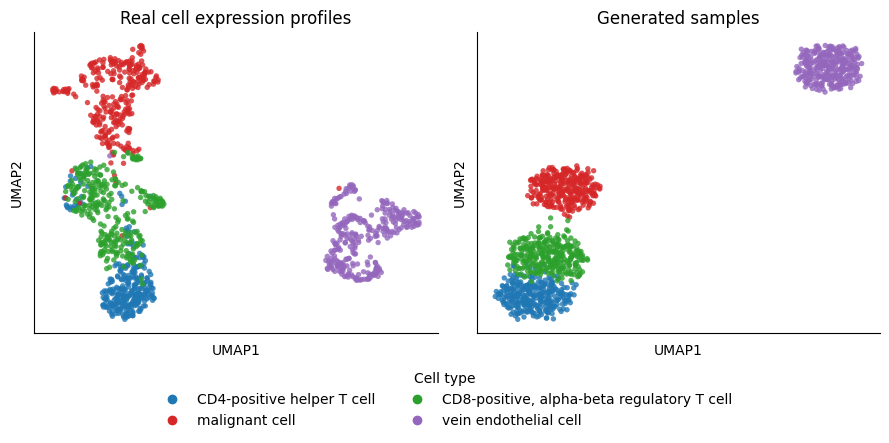

In [6]:
# Keep the category order and palette identical in both AnnData objects
for adata in (adata_umap_real, adata_umap):
    adata.obs["cell_type"] = adata.obs["cell_type"].cat.set_categories(cell_types, ordered=True)
    adata.uns["cell_type_colors"] = cell_type_colors

fig, (ax_real, ax_generated) = plt.subplots(ncols=2, figsize=(9, 4.5))

sc.pl.umap(
    adata_umap_real,
    color="cell_type",
    title="Real cell expression profiles",
    size=60,
    alpha=0.8,
    frameon=False,
    legend_loc=None,
    ax=ax_real,
    show=False,
)
ax_real.set_axis_on()
ax_real.set_xlabel("UMAP1")
ax_real.set_ylabel("UMAP2")

sc.pl.umap(
    adata_umap,
    color="cell_type",
    title="Generated samples",
    size=60,
    alpha=0.8,
    frameon=False,
    legend_loc=None,
    ax=ax_generated,
    show=False,
)
ax_generated.set_axis_on()
ax_generated.set_xlabel("UMAP1")
ax_generated.set_ylabel("UMAP2")

for ax in (ax_real, ax_generated):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Legend
handles = [
    Line2D(
        [], [],
        marker="o",
        linestyle="",
        color=color,
        label=cell_type,
        markersize=6,
    )
    for cell_type, color in zip(cell_types, cell_type_colors)
]

fig.legend(
    handles=handles,
    title="Cell type",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=2,
    frameon=False,
)

fig.tight_layout(rect=[0, 0.16, 1, 1])
fig.savefig(OUTPUT_DIR / "combined_umap.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "combined_umap.svg", dpi=300, bbox_inches="tight", format="svg")
plt.show()